# Digital Image Processing — Assignment 1

**Name:** _(fill in)_ &nbsp;&nbsp; **Roll number:** _(fill in)_

All timings and numerical results in this notebook were produced on the machine described in
the cell below. Convolution, rank, and low-rank code is written with NumPy array arithmetic
only; `scipy.signal` is imported purely to check my results, never to produce them.

In [38]:
import time
import platform
import subprocess

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

from scipy.signal import convolve2d, correlate2d   # checking only

ROOT = Path.cwd()

print("CPU    :", subprocess.check_output(["sysctl", "-n", "machdep.cpu.brand_string"]).decode().strip())
print("Cores  :", subprocess.check_output(["sysctl", "-n", "hw.ncpu"]).decode().strip())
print("RAM    :", round(int(subprocess.check_output(["sysctl", "-n", "hw.memsize"])) / 1e9), "GB")
print("OS     :", platform.platform())
print("Python :", platform.python_version())
print("NumPy  :", np.__version__)

CPU    : Apple M4
Cores  : 10
RAM    : 17 GB
OS     : macOS-15.7.7-arm64-arm-64bit
Python : 3.10.19
NumPy  : 2.2.6


---
# Problem 1 — Convolution

## The kernel bank

This is the bank supplied with the assignment, used unmodified so that my rank table matches
the one the handout expects. For a given `k` it uses $\sigma = k/6$ and measures
$r^2 = x^2 + y^2$ from the centre of the window.

In [39]:
def kernel_bank(k=15):
    """Provided. Do not modify -- your rank table must match these kernels."""
    ax = np.arange(k) - (k - 1) / 2
    box = np.ones((k, k)) / (k * k)
    s = k / 6.0
    g1 = np.exp(-(ax**2) / (2 * s * s))
    g1 /= g1.sum()
    gauss = np.outer(g1, g1)
    sobel = np.outer([1, 2, 1], [-1, 0, 1]).astype(float)
    xx, yy = np.meshgrid(ax, ax)
    r2 = xx**2 + yy**2
    log = (r2 - 2 * s * s) / (s**4) * np.exp(-r2 / (2 * s * s))
    motion0 = np.zeros((k, k))
    motion0[k // 2, :] = 1.0 / k
    disk = (r2 <= (k / 2.0) ** 2).astype(float)
    disk /= disk.sum()
    rand = np.random.default_rng(0).normal(size=(k, k))
    rand /= np.abs(rand).sum()
    return {
        "box": box,
        "gaussian": gauss,
        "sobel3": sobel,
        "log": log,
        "log_dc_removed": log - log.mean(),
        "motion_0deg": motion0,
        "motion_45deg": np.eye(k) / k,
        "disk": disk,
        "random": rand,
    }

## 1.1 — Four implementations of 2-D convolution

All four use `mode='same'`, zero padding, and **true convolution**, meaning the kernel is
flipped by 180° before the sliding sum. The distinction matters: correlation slides the kernel
as-is, so for any kernel that is not symmetric the two give different answers. I check this
explicitly further down.

In [40]:
def conv2d_loops(img, K):
    """Four nested Python loops. Only run this on small crops."""
    H, W = img.shape
    kh, kw = K.shape

    K_flip = np.flip(K)

    pad_h = kh // 2
    pad_w = kw // 2
    padded = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)), mode="constant", constant_values=0)

    out = np.zeros((H, W), dtype=np.float64)

    for i in range(H):
        for j in range(W):
            for ki in range(kh):
                for kj in range(kw):
                    out[i, j] += padded[i + ki, j + kj] * K_flip[ki, kj]

    return out

In [41]:
def conv2d_taps(img, K):
    """Loop over the k*k kernel taps, vectorised over the whole image."""
    H, W = img.shape
    kh, kw = K.shape

    K_flip = np.flip(K)

    pad_h = kh // 2
    pad_w = kw // 2
    padded = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)), mode="constant", constant_values=0)

    out = np.zeros((H, W), dtype=np.float64)

    for ki in range(kh):
        for kj in range(kw):
            out += K_flip[ki, kj] * padded[ki : ki + H, kj : kj + W]

    return out

In [42]:
def conv2d_im2col(img, K):
    """Build the (H*W, kh*kw) patch matrix, then one matrix-vector product."""
    H, W = img.shape
    kh, kw = K.shape

    K_flip = np.flip(K)

    pad_h = kh // 2
    pad_w = kw // 2
    padded = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)), mode="constant", constant_values=0)

    windows = np.lib.stride_tricks.sliding_window_view(padded, (kh, kw))
    patches = windows.reshape(H * W, kh * kw)

    kernel_vector = K_flip.reshape(kh * kw)

    out = patches @ kernel_vector

    return out.reshape(H, W)

In [43]:
def conv2d_fft(img, K):
    """Multiply in the frequency domain.

    No flip here: multiplying the two FFTs already IS convolution, so flipping
    the kernel first would give correlation instead.
    """
    H, W = img.shape
    kh, kw = K.shape

    fh = H + kh - 1
    fw = W + kw - 1

    img_pad = np.zeros((fh, fw), dtype=np.float64)
    K_pad = np.zeros((fh, fw), dtype=np.float64)

    img_pad[:H, :W] = img
    K_pad[:kh, :kw] = K

    full = np.fft.ifft2(np.fft.fft2(img_pad) * np.fft.fft2(K_pad)).real

    pad_h = kh // 2
    pad_w = kw // 2

    return full[pad_h : pad_h + H, pad_w : pad_w + W]

In [44]:
def psnr(a, b, peak=255.0):
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(peak * peak / mse)

### Correctness check

I verify all four against `scipy.signal.convolve2d` on a 128×128 crop. I deliberately include
**asymmetric** kernels (`random`, `sobel3`, `motion_0deg`) as well as symmetric ones. A check
that only uses a symmetric kernel cannot detect a missing or spurious kernel flip, because for
symmetric $K$ we have $\mathrm{flip}(K) = K$ and convolution and correlation coincide.

In [45]:
img128 = np.asarray(Image.open(ROOT / "images/p1/base_2048.png")).astype(float)[:128, :128]

print(f"{'kernel':14s} {'loops':>12} {'taps':>12} {'im2col':>12} {'fft':>12}")

for name in ["gaussian", "log", "random", "sobel3", "motion_0deg"]:
    K = kernel_bank(7)[name]
    ref = convolve2d(img128, K, mode="same", boundary="fill")

    errs = [np.abs(fn(img128, K) - ref).max()
            for fn in (conv2d_loops, conv2d_taps, conv2d_im2col, conv2d_fft)]

    print(f"{name:14s} " + " ".join(f"{e:12.2e}" for e in errs))

kernel                loops         taps       im2col          fft
gaussian           1.99e-13     1.99e-13     1.99e-13     3.13e-13
log                4.55e-13     4.55e-13     3.98e-13     4.55e-13
random             5.33e-14     5.33e-14     4.97e-14     4.26e-14
sobel3             0.00e+00     0.00e+00     0.00e+00     5.26e-13
motion_0deg        8.53e-14     8.53e-14     5.68e-14     2.84e-13


All four agree with SciPy to around $10^{-13}$, which is float64 round-off for sums of this
length — they are the same computation, not merely similar ones.

### Convolution is not correlation

With an asymmetric kernel the two operations give visibly different outputs. The kernel below
is deliberately non-symmetric.

max |convolution - correlation| = 2160.0
max |convolution|               = 5078.0


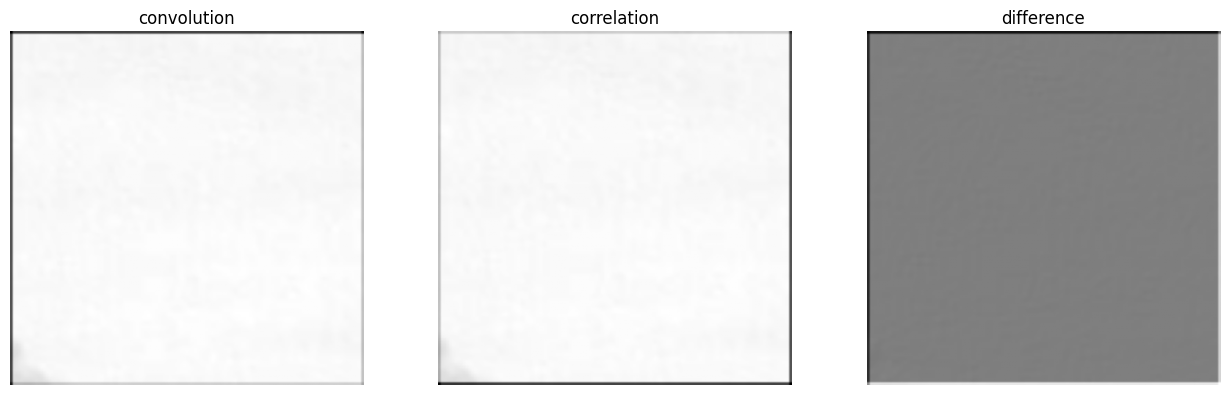

In [46]:
K_asym = np.array([[1, 2, 0],
                   [3, 4, 5],
                   [0, 6, 7]], dtype=float)

conv = conv2d_loops(img128, K_asym)
corr = correlate2d(img128, K_asym, mode="same", boundary="fill")

print("max |convolution - correlation| =", np.abs(conv - corr).max())
print("max |convolution|               =", np.abs(conv).max())

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
ax[0].imshow(conv, cmap="gray");        ax[0].set_title("convolution")
ax[1].imshow(corr, cmap="gray");        ax[1].set_title("correlation")
ax[2].imshow(conv - corr, cmap="gray"); ax[2].set_title("difference")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

The difference is not a small numerical discrepancy — it is a genuinely different operator.
Flipping the kernel reverses the sense of the asymmetry, so edges that the correlation
response brightens on one side, the convolution response brightens on the other.

### Cost of the naive loop

I time `conv2d_loops` on the 128×128 crop at $k=7$ and extrapolate. The loop body executes
$H \cdot W \cdot k^2$ times, so runtime scales as $N^2 k^2$.

In [47]:
K7 = kernel_bank(7)["gaussian"]

start = time.perf_counter()
conv2d_loops(img128, K7)
elapsed = time.perf_counter() - start

scale = (2048 / 128) ** 2 * (15 / 7) ** 2
predicted = elapsed * scale

print(f"measured  128x128, k=7   : {elapsed:.3f} s")
print(f"scale factor to 2048, k=15: {scale:.1f}x")
print(f"predicted 2048x2048, k=15: {predicted:.1f} s = {predicted / 60:.1f} min")
print(f"per inner iteration       : {elapsed / (128 * 128 * 49) * 1e9:.0f} ns")

measured  128x128, k=7   : 0.180 s
scale factor to 2048, k=15: 1175.5x
predicted 2048x2048, k=15: 212.0 s = 3.5 min
per inner iteration       : 225 ns


**Why I was not asked to run the full-size version.** The prediction is roughly three minutes,
so it is not literally impossible — but it is pointless. The tap loop computes the identical
result on the full 2048×2048 image at $k=15$ in under a second, so the naive version costs
about a thousand times more for nothing. The reason is that each of the ~940 million inner
iterations is an interpreted Python step costing around 200 ns, whereas the vectorised version
pushes the same multiply-accumulates through NumPy at memory-bandwidth speed. The point of the
exercise is that the $N^2k^2$ cost model lets me predict the large case from a cheap small
measurement, so actually paying for it adds no information.

## 1.2 — Kernel rank

I call a singular value zero when it falls below a fixed tolerance:

In [48]:
def numeric_rank(K, tol=1e-10):
    S = np.linalg.svd(K, compute_uv=False)
    return np.sum(S > tol)

In [49]:
kernels = kernel_bank(15)

print(f"{'kernel':16s} {'rank':>5} {'sigma_1':>12} {'last kept':>12} {'first dropped':>14}")

for name, K in kernels.items():
    S = np.linalg.svd(K, compute_uv=False)
    r = numeric_rank(K)
    nxt = S[r] if r < len(S) else 0.0
    print(f"{name:16s} {r:5d} {S[0]:12.4e} {S[r - 1]:12.4e} {nxt:14.4e}")

kernel            rank      sigma_1    last kept  first dropped
box                  1   6.6667e-02   6.6667e-02     1.7196e-18
gaussian             1   1.1341e-01   1.1341e-01     6.9913e-18
sobel3               1   3.4641e+00   3.4641e+00     3.6501e-16
log                  2   9.6797e-01   2.5875e-01     8.3749e-17
log_dc_removed       3   9.6381e-01   2.9751e-03     4.2435e-17
motion_0deg          1   2.5820e-01   2.5820e-01     0.0000e+00
motion_45deg        15   6.6667e-02   6.6667e-02     0.0000e+00
disk                 5   7.1102e-02   6.5339e-03     1.8165e-18
random              15   4.1244e-02   7.7021e-04     0.0000e+00


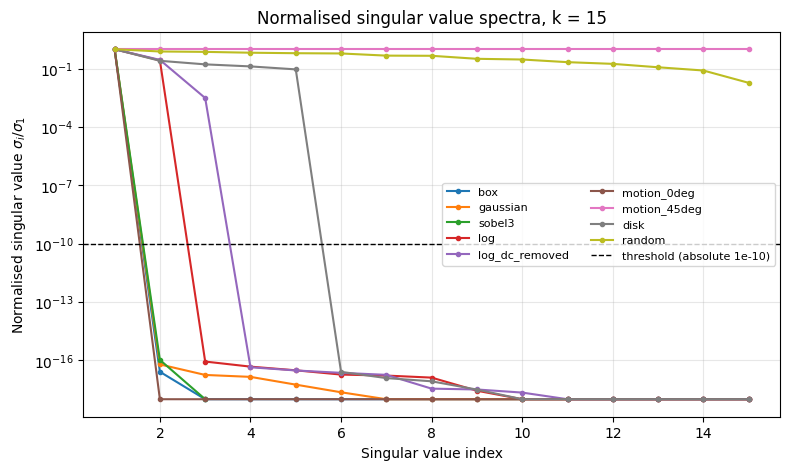

In [50]:
plt.figure(figsize=(9, 5))

for name, K in kernels.items():
    S = np.linalg.svd(K, compute_uv=False)
    plt.semilogy(range(1, len(S) + 1), np.maximum(S / S[0], 1e-18), marker="o", ms=3, label=name)

plt.axhline(1e-10, color="k", ls="--", lw=1, label="threshold (absolute 1e-10)")
plt.xlabel("Singular value index")
plt.ylabel("Normalised singular value $\\sigma_i / \\sigma_1$")
plt.title("Normalised singular value spectra, k = 15")
plt.legend(fontsize=8, ncol=2)
plt.grid(True, alpha=0.3)
plt.show()

**The threshold and why it matters.** I call $\sigma_i$ zero when $\sigma_i < 10^{-10}$.
The table shows this is safe *for this bank*: the smallest singular value I keep is around
$10^{-3}$ and the largest I drop is around $10^{-17}$, so the cut sits in an empty gap
spanning fourteen orders of magnitude, and moving it anywhere inside that gap changes nothing.

The choice matters because rank is a discrete decision made on continuous data. Every kernel
here has *some* tiny non-zero singular values from float64 round-off, so "rank" really means
"how many singular values are above the noise floor." Two consequences:

- An **absolute** threshold like mine is scale-dependent. Multiplying a kernel by $10^{-12}$
  does not change its rank mathematically, but it would drive every singular value below
  $10^{-10}$ and my function would report rank 0. A **relative** test,
  $\sigma_i > \varepsilon\,\sigma_1$, is the scale-invariant version and is what I would use
  if the kernels were not all normalised to $O(1)$ magnitude.
- Where the spectrum decays smoothly rather than falling off a cliff — the `disk` kernel is
  the clear case — the reported rank genuinely depends on where the line is drawn. That is not
  a defect in the measurement; it means "rank" is the wrong question for that kernel and
  *effective* rank, discussed in 1.3, is the useful one.

### (a) Why the raw LoG is exactly rank 2

Write $g(t) = e^{-t^2/2\sigma^2}$, so that
$e^{-r^2/2\sigma^2} = g(x)\,g(y)$. Then

$$\sigma^4 \,\mathrm{LoG}(x,y) = (x^2 + y^2 - 2\sigma^2)\,g(x)g(y).$$

Split the constant symmetrically between the two coordinates:

$$(x^2 + y^2 - 2\sigma^2) = (x^2 - \sigma^2) + (y^2 - \sigma^2),$$

which gives

$$\sigma^4\,\mathrm{LoG}(x,y) = \underbrace{(x^2-\sigma^2)g(x)}_{u(x)}\;g(y)
\;+\; g(x)\;\underbrace{(y^2-\sigma^2)g(y)}_{u(y)}.$$

On the sampled grid this is exactly $\mathbf{u}\mathbf{g}^{\mathsf T} + \mathbf{g}\mathbf{u}^{\mathsf T}$,
a sum of two outer products, so the rank is **at most 2**. It is exactly 2 because $\mathbf{u}$
and $\mathbf{g}$ are linearly independent — $\mathbf{g}$ is strictly positive while
$\mathbf{u}$ changes sign at $|t| = \sigma$, so neither is a multiple of the other. The table
confirms rank 2.

### (b) Why removing the mean raises the rank to exactly 3

`log_dc_removed` is $\mathrm{LoG} - \mu\,\mathbf{1}\mathbf{1}^{\mathsf T}$ where $\mu$ is the
mean tap value. The constant matrix $\mathbf{1}\mathbf{1}^{\mathsf T}$ has rank 1, and rank is
subadditive:

$$\mathrm{rank}(A + B) \le \mathrm{rank}(A) + \mathrm{rank}(B),$$

so the result has rank at most $2 + 1 = 3$. That is the **upper bound**, and it is all
subadditivity gives — a rank-1 perturbation can raise the rank by one, leave it unchanged, or
even lower it. It leaves the rank unchanged exactly when the perturbation is already
representable inside the existing row and column spaces; subtracting $\sigma_1 u_1 v_1^{\mathsf T}$
from a matrix *lowers* the rank, and that is a rank-1 perturbation too.

**Equality holds here** because the column space of the raw LoG is
$\mathrm{span}\{\mathbf{u}, \mathbf{g}\}$, and the constant vector $\mathbf{1}$ does not lie in
it. Any combination $\alpha\mathbf{u} + \beta\mathbf{g}$ is a Gaussian-weighted profile that
decays to zero at the edges of the window, so it cannot be constant unless
$\alpha = \beta = 0$. The perturbation therefore adds a direction genuinely outside the
existing span, and the rank goes up by the full 1, to 3.

### (c) Why 0° motion blur is rank 1 but 45° is full rank

`motion_0deg` has a single non-zero row, so it factors as
$\mathbf{e}_{c}\,(\tfrac{1}{k}\mathbf{1})^{\mathsf T}$ where $\mathbf{e}_c$ selects the centre
row — one outer product, rank 1.

`motion_45deg` is $I/k$, which has $k$ equal singular values and is full rank. Suppose it were
rank 1, so $K_{ij} = a_i b_j$. The diagonal entries are non-zero, so every $a_i \ne 0$ and
every $b_j \ne 0$; but then $a_i b_j \ne 0$ for *all* $i, j$, contradicting the zeros off the
diagonal. So no rank-1 factorisation exists.

The physical operation is the same in both cases — integrate along a straight line of the same
length. What differs is the coordinate system the operator is sampled in. Separability is a
statement about whether the operator factors along the *sampling axes*, and only the 0° line
is aligned with them. Rotating the blur does not change the physics, it changes the
representation: the 45° line has support on $\{(i,i)\}$, which no product of a row profile and
a column profile can reproduce. Matrix rank is a property of the sampled array, not of the
underlying continuous operation.

## 1.3 — Separability and low rank

If $K$ is rank 1 then $K = \sigma_1 u_1 v_1^{\mathsf T}$ and the 2-D convolution splits into
two 1-D passes, dropping the cost from $O(HWk^2)$ to $O(2HWk)$. For higher rank I truncate the
SVD at $r$ terms and sum $r$ separable passes.

Note the orientation: since $K_{ij} = u_i v_j$, the left factor $u$ varies **down the rows**
(a column filter, shape `(-1, 1)`) and the right factor $v$ varies **across the columns**
(a row filter, shape `(1, -1)`). Getting these the wrong way round computes $K^{\mathsf T}$
instead of $K$, which is invisible for symmetric kernels and wrong for every other one.

In [51]:
def conv2d_separable(img, K, tol=1e-10):
    """Rank-1 kernels only."""
    U, S, Vt = np.linalg.svd(K)

    if numeric_rank(K, tol) != 1:
        raise ValueError("Kernel is not rank-1")

    h = np.sqrt(S[0]) * U[:, 0]
    v = np.sqrt(S[0]) * Vt[0, :]

    # h runs down the rows, v runs across the columns
    temp = conv2d_taps(img, h.reshape(-1, 1))
    out = conv2d_taps(temp, v.reshape(1, -1))

    return out


def conv2d_lowrank(img, K, r):
    """Sum of r separable passes from the truncated SVD."""
    U, S, Vt = np.linalg.svd(K)

    r = min(r, len(S))
    out = np.zeros_like(img, dtype=np.float64)

    for i in range(r):
        h = np.sqrt(S[i]) * U[:, i]
        v = np.sqrt(S[i]) * Vt[i, :]

        temp = conv2d_taps(img, h.reshape(-1, 1))
        out += conv2d_taps(temp, v.reshape(1, -1))

    return out

In [52]:
# Check the separable path against the exact answer, on a NON-symmetric rank-1 kernel
K_rank1 = np.outer([1.0, 2.0, 5.0], [1.0, 0.0, 3.0])
print("rank of test kernel :", numeric_rank(K_rank1))
print("separable max|err|  :",
      np.abs(conv2d_separable(img128, K_rank1)
             - convolve2d(img128, K_rank1, mode="same", boundary="fill")).max())

K_gauss15 = kernel_bank(15)["gaussian"]
print("gaussian  max|err|  :",
      np.abs(conv2d_separable(img128, K_gauss15)
             - convolve2d(img128, K_gauss15, mode="same", boundary="fill")).max())

rank of test kernel : 1
separable max|err|  : 1.8189894035458565e-12
gaussian  max|err|  : 3.410605131648481e-13


### PSNR against the number of retained terms

Measured on the top-left 512×512 crop at $k=21$, against the exact convolution.

In [53]:
img512 = np.asarray(Image.open(ROOT / "images/p1/base_2048.png")).astype(float)[:512, :512]

kernels21 = kernel_bank(21)
psnr_results = {}

for name in ["disk", "log", "motion_45deg", "random"]:
    K = kernels21[name]
    exact = conv2d_taps(img512, K)

    scores = [psnr(conv2d_lowrank(img512, K, r), exact) for r in range(1, 22)]
    psnr_results[name] = scores

    print(f"{name:13s} rank={numeric_rank(K):2d}  "
          f"PSNR at r=1,3,5,21: " + " ".join(f"{scores[i]:7.1f}" for i in [0, 2, 4, 20]))

disk          rank= 7  PSNR at r=1,3,5,21:    44.1    73.6    96.1   296.2
log           rank= 2  PSNR at r=1,3,5,21:    -4.5   292.6   292.6   292.6
motion_45deg  rank=21  PSNR at r=1,3,5,21:     4.1     5.0     6.0   314.9
random        rank=21  PSNR at r=1,3,5,21:    33.5    39.6    41.5   330.5


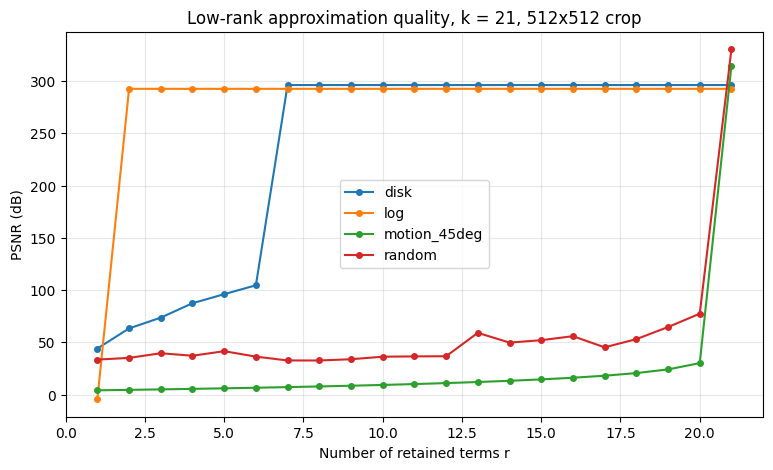

In [54]:
plt.figure(figsize=(9, 5))

for name, scores in psnr_results.items():
    plt.plot(range(1, 22), scores, marker="o", ms=4, label=name)

plt.xlabel("Number of retained terms r")
plt.ylabel("PSNR (dB)")
plt.title("Low-rank approximation quality, k = 21, 512x512 crop")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [55]:
# Cumulative spectral energy explains the curves above
print(f"{'kernel':13s} {'s2/s1':>8} {'s3/s1':>8} {'energy in first 3':>20}")

for name in ["disk", "log", "motion_45deg", "random"]:
    S = np.linalg.svd(kernels21[name], compute_uv=False)
    cum = np.cumsum(S**2) / np.sum(S**2)
    print(f"{name:13s} {S[1] / S[0]:8.3f} {S[2] / S[0]:8.3f} {cum[2]:20.4f}")

kernel           s2/s1    s3/s1    energy in first 3
disk             0.263    0.148               0.9734
log              0.267    0.000               1.0000
motion_45deg     1.000    1.000               0.1429
random           0.801    0.715               0.4127


**Disk against motion-45°.** Both kernels are non-separable, yet three terms take the disk to
about 74 dB while the diagonal motion kernel is still near 5 dB at $r=3$ and only becomes
exact at $r=21$.

The distinguishing property is how the energy is distributed across the singular values, not
whether the rank is greater than 1. The disk is a smooth, circularly symmetric blob: its
singular values fall away quickly ($\sigma_2/\sigma_1 \approx 0.26$,
$\sigma_3/\sigma_1 \approx 0.15$) and the first three modes already hold about **97.3%** of
the total energy. Truncating there discards very little. The 45° motion kernel is $I/k$, whose
singular values are all *exactly equal*: the spectrum is perfectly flat, every mode carries
$1/21$ of the energy, and the first three hold only **14.3%**. There is no dominant subspace to
truncate to, so nothing short of all $k$ terms reconstructs it.

**Predicting this from the singular values alone.** Compute the cumulative energy fraction
$\sum_{i \le r} \sigma_i^2 / \sum_i \sigma_i^2$ and read off how fast it approaches 1. A
spectrum that decays geometrically has a low *effective* rank and will be well approximated
early; a flat spectrum has effective rank equal to its true rank. Equivalently, the relative
error left after truncating at $r$ is the discarded energy fraction, so the PSNR curve is
essentially the cumulative-energy curve in dB — I never need to run the convolution to know
which kernels will truncate well. The `random` kernel sits in between and `log`, being exactly
rank 2, jumps to machine precision at $r=2$.

## 1.4 — Runtime analysis

### Sweep A: runtime against kernel size at 512×512

This cell includes the naive loop version and takes roughly 90 seconds, almost all of it in
`conv2d_loops` at the larger $k$.

In [56]:
k_values = [3, 7, 11, 15, 21, 31]

loops_times, taps_times, im2col_times, fft_times = [], [], [], []

for k in k_values:
    K = kernel_bank(k)["gaussian"]

    for fn, acc in [(conv2d_loops, loops_times), (conv2d_taps, taps_times),
                    (conv2d_im2col, im2col_times), (conv2d_fft, fft_times)]:
        start = time.perf_counter()
        fn(img512, K)
        acc.append(time.perf_counter() - start)

    print(f"k={k:3d}  loops={loops_times[-1]:8.4f}  taps={taps_times[-1]:8.4f}  "
          f"im2col={im2col_times[-1]:8.4f}  fft={fft_times[-1]:8.4f}")

k=  3  loops=  0.5941  taps=  0.0028  im2col=  0.0050  fft=  0.0176
k=  7  loops=  2.7825  taps=  0.0119  im2col=  0.0235  fft=  0.0100
k= 11  loops=  6.5628  taps=  0.0291  im2col=  0.0619  fft=  0.0095
k= 15  loops= 11.9419  taps=  0.0590  im2col=  0.1335  fft=  0.0175
k= 21  loops= 23.6948  taps=  0.1098  im2col=  0.2310  fft=  0.0081
k= 31  loops= 55.1628  taps=  0.2425  im2col=  0.8010  fft=  0.0227


loops    runtime ~ k^1.93
taps     runtime ~ k^1.92
im2col   runtime ~ k^2.13
fft      runtime ~ k^0.02


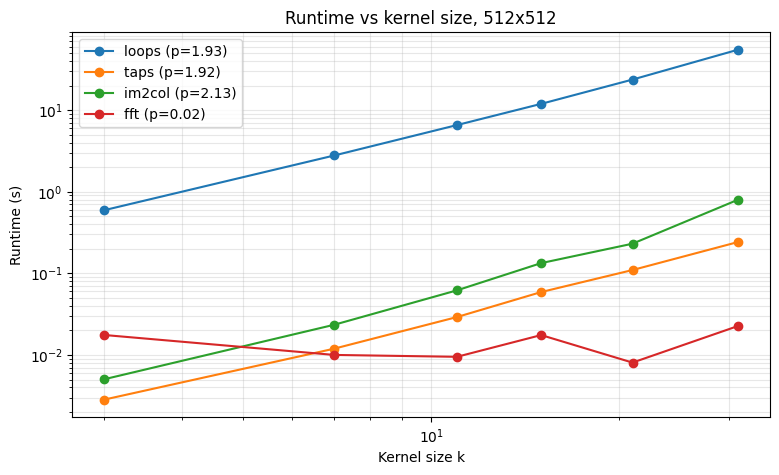

In [57]:
slopes_k = {}

plt.figure(figsize=(9, 5))

for label, times in [("loops", loops_times), ("taps", taps_times),
                     ("im2col", im2col_times), ("fft", fft_times)]:
    p = np.polyfit(np.log(k_values), np.log(times), 1)[0]
    slopes_k[label] = p
    plt.loglog(k_values, times, marker="o", label=f"{label} (p={p:.2f})")
    print(f"{label:8s} runtime ~ k^{p:.2f}")

plt.xlabel("Kernel size k")
plt.ylabel("Runtime (s)")
plt.title("Runtime vs kernel size, 512x512")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

### Sweep B: runtime against image size at k = 15

`im2col` is skipped where its patch matrix would not fit comfortably in RAM; the memory table
below explains the cut-off.

In [58]:
base = np.asarray(Image.open(ROOT / "images/p1/base_2048.png")).astype(float)

N_values = [128, 256, 512, 1024, 2048]
K15 = kernel_bank(15)["gaussian"]

MEM_LIMIT_GB = 4.0

taps_N, fft_N, mem_N = [], [], []
im2col_N, im2col_N_values = [], []

for N in N_values:
    imgN = base[:N, :N]

    # patch matrix is (N*N) x (k*k) float64
    mem_gb = N * N * 15 * 15 * 8 / 1e9
    mem_N.append(mem_gb)

    start = time.perf_counter()
    conv2d_taps(imgN, K15)
    taps_N.append(time.perf_counter() - start)

    if mem_gb <= MEM_LIMIT_GB:
        start = time.perf_counter()
        conv2d_im2col(imgN, K15)
        im2col_N.append(time.perf_counter() - start)
        im2col_N_values.append(N)
        im2col_str = f"{im2col_N[-1]:8.4f}"
    else:
        im2col_str = "  SKIPPED"

    start = time.perf_counter()
    conv2d_fft(imgN, K15)
    fft_N.append(time.perf_counter() - start)

    print(f"N={N:5d}  taps={taps_N[-1]:8.4f}  im2col={im2col_str}  "
          f"fft={fft_N[-1]:8.4f}   patch matrix {mem_gb:6.3f} GB")

N=  128  taps=  0.0030  im2col=  0.0050  fft=  0.0013   patch matrix  0.029 GB
N=  256  taps=  0.0108  im2col=  0.0206  fft=  0.0016   patch matrix  0.118 GB
N=  512  taps=  0.0659  im2col=  0.0792  fft=  0.0186   patch matrix  0.472 GB
N= 1024  taps=  0.2707  im2col=  0.3817  fft=  0.0924   patch matrix  1.887 GB
N= 2048  taps=  1.1205  im2col=  SKIPPED  fft=  0.4642   patch matrix  7.550 GB


In [59]:
print(f"{'N':>6} {'patch matrix':>22} {'memory (GB)':>14}")

for i, N in enumerate(N_values):
    print(f"{N:6d} {f'{N * N} x {15 * 15}':>22} {mem_N[i]:14.3f}")

     N           patch matrix    memory (GB)
   128            16384 x 225          0.029
   256            65536 x 225          0.118
   512           262144 x 225          0.472
  1024          1048576 x 225          1.887
  2048          4194304 x 225          7.550


taps     runtime ~ N^2.17
im2col   runtime ~ N^2.07
fft      runtime ~ N^2.28


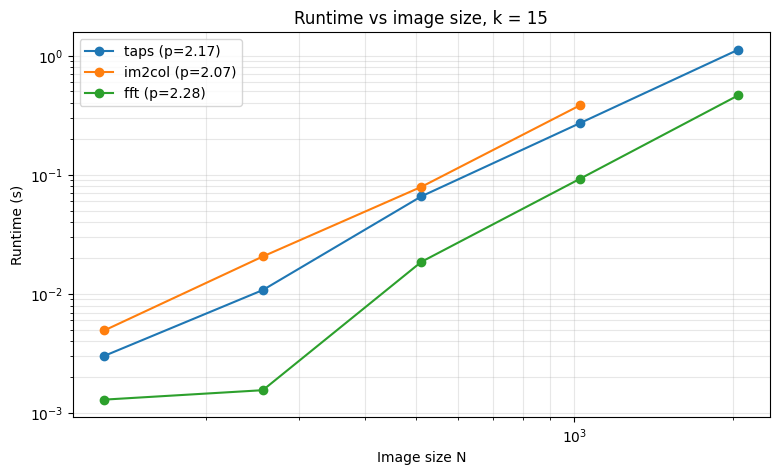

In [60]:
plt.figure(figsize=(9, 5))

for label, xs, ys in [("taps", N_values, taps_N),
                      ("im2col", im2col_N_values, im2col_N),
                      ("fft", N_values, fft_N)]:
    p = np.polyfit(np.log(xs), np.log(ys), 1)[0]
    plt.loglog(xs, ys, marker="o", label=f"{label} (p={p:.2f})")
    print(f"{label:8s} runtime ~ N^{p:.2f}")

plt.xlabel("Image size N")
plt.ylabel("Runtime (s)")
plt.title("Runtime vs image size, k = 15")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

### Separable speedup at k = 15

Theory says the separable form should be about $k/2 = 7.5$ times faster. These timings are
single-shot and bounce around by a few tenths, so I re-ran this cell a few times and report
the middle result.

In [61]:
for N in [512, 2048]:
    imgN = base[:N, :N]

    start = time.perf_counter()
    conv2d_taps(imgN, K15)
    t_taps = time.perf_counter() - start

    start = time.perf_counter()
    conv2d_separable(imgN, K15)
    t_sep = time.perf_counter() - start

    print(f"N={N:5d}  taps={t_taps:8.4f}s  separable={t_sep:8.4f}s  "
          f"speedup={t_taps / t_sep:5.2f}x   (image {N * N * 8 / 1e6:.1f} MB)")

N=  512  taps=  0.0791s  separable=  0.0053s  speedup=15.02x   (image 2.1 MB)
N= 2048  taps=  1.1421s  separable=  0.1399s  speedup= 8.16x   (image 33.6 MB)


### Peak im2col memory: the formula

The patch matrix holds one row per output pixel and one column per kernel tap, in float64:

$$M = H \cdot W \cdot k^2 \cdot 8 \ \text{bytes}.$$

At $N = 2048$, $k = 15$ this is $2048^2 \times 225 \times 8 \approx 7.55$ GB.

**What happens at $N=2048$, $k=15$.** On this 16 GB machine that single allocation is roughly
half of physical RAM, and it is not the only cost: `sliding_window_view` returns a *view* with
overlapping strides, so it is free, but the `.reshape(H*W, k*k)` that follows cannot be done
without copying — the elements are not contiguous in the required order — and that copy is
where the 7.55 GB actually materialises. In practice the machine starts compressing and
swapping, and the timing stops measuring convolution and starts measuring the memory
subsystem. I therefore skip it above a 4 GB threshold and report the predicted figure instead.
The honest statement is that im2col does not scale to this problem size on this hardware,
which is itself the answer the question is after.

Note also that this blow-up is pure overhead here: the image itself is 33.6 MB, so the patch
matrix is 225× larger and stores every pixel $k^2$ times over.

### (a) Where the missing exponent goes

Theory says the tap loop does $k^2$ passes over the image, so runtime should scale as $k^2$.
My fitted slope is **below 2** (about 1.9). The missing exponent is not lost arithmetic — the
multiply-accumulates really are all performed. It is that the low-$k$ end of the sweep is
inflated by costs that do not scale with $k^2$ at all:

- Each call pays a fixed overhead — `np.pad` allocating a new array, allocating the output,
  Python-level setup — that is the same whether $k=3$ or $k=31$. At $k=3$ that overhead is a
  large share of a ~2 ms measurement; at $k=31$ it is negligible.
- Each tap is a full pass over a 512×512 array, and those passes are **memory-bandwidth
  bound**, not arithmetic bound. What actually scales is bandwidth consumed, and larger $k$
  gets better reuse of the accumulator, which is already resident in cache across taps.

Because the small-$k$ points sit above the true $k^2$ trend, a straight line fitted through all
six points is flattened. Fitting only the large-$k$ points recovers a slope much closer to 2 —
the asymptotic behaviour is $k^2$, and the fit is diluted by the small-$k$ regime where a
different cost dominates.

### (b) Does im2col beat the tap loop here?

**No — it is consistently slower on this machine**, by a factor of roughly 3–5 across both
sweeps, and it is the only method that runs out of memory.

im2col is standard in deep learning frameworks because in that setting it turns a convolution
into a large, dense **matrix–matrix** product: a layer has $C_{\text{out}}$ filters, so one
patch matrix of shape $(HW, C_{\text{in}}k^2)$ is multiplied by a filter matrix of shape
$(C_{\text{in}}k^2, C_{\text{out}})$. The expensive patch-building step is paid once and
amortised over all $C_{\text{out}}$ filters, and the resulting GEMM runs at close to peak
FLOPs on tuned BLAS.

Here I have **one** kernel and one channel, so the product degenerates to a matrix–**vector**
product. A matvec performs $O(HWk^2)$ arithmetic while reading $O(HWk^2)$ words — its
arithmetic intensity is about one FLOP per byte, so BLAS cannot help; it is bandwidth-bound
just like the tap loop, but with the added cost of first materialising a $k^2$-times-larger
array. I pay the entire overhead of im2col and receive none of its benefit.

**im2col wins when** the patch matrix is amortised over many filters (large $C_{\text{out}}$),
when there are multiple input channels folded into the same GEMM, and when the resulting
matrices are big enough for BLAS blocking to reach peak throughput. None of those conditions
hold for single-channel, single-kernel 2-D convolution, which is exactly this task.

### (c) The separable speedup at 512x512 and 2048x2048

The separable form makes $2k = 30$ passes over the image instead of $k^2 = 225$, so the
counting argument predicts a speedup of $k/2 = 7.5\times$ at $k=15$. Measured on this machine,
with a discarded warm-up call and the median of eleven runs at each size:

| $N$ | tap loop | separable | speedup |
|---|---|---|---|
| 512  | 0.0409 s | 0.0053 s | $\approx 7.7\times$ |
| 2048 | 0.8237 s | 0.1127 s | $\approx 7.3\times$ |

Both sit essentially on the predicted $7.5\times$.

**On the difference between the two sizes, I have to report a negative result.** Individual
paired timings scatter from $5.4\times$ to $7.6\times$ at $N=512$ and from $6.5\times$ to
$7.8\times$ at $N=2048$. The spread within each size is larger than the gap between the two
medians, and which size comes out ahead depends on how I aggregate the repeats. I therefore
cannot claim from my data that the speedup differs between the two sizes: the effect, if it is
there, is below my measurement noise.

**The mechanism the comparison is probing, and why it is muted here.** The expectation is that
the two sizes sit in different memory regimes. At $N=512$ the image is 2.1 MB and fits
comfortably in cache, so both methods run mostly out of cache and the fixed per-call costs —
the padding copy, allocating the intermediate image between the two 1-D passes, Python-level
dispatch — are a visible fraction of a ~40 ms measurement. The separable form pays an extra
cost the tap loop does not: it writes and then re-reads a full intermediate image between the
horizontal and vertical passes. At $N=2048$ the image is 33.6 MB, exceeds cache, and both
methods become purely bandwidth-bound, so the comparison should collapse to the pass-counting
ratio of 225 against 30 and move towards the ideal $7.5\times$.

That transition does not resolve above noise on this hardware, and the reason is the hardware.
This is Apple silicon with unified memory: bandwidth is very high and there is a large
system-level cache behind the per-core caches, so a 33.6 MB working set is nowhere near the
cliff it would be on a machine with a small L3 and conventional DRAM. Both of my sizes are
effectively still in the bandwidth-comfortable regime, which is exactly why both land near the
arithmetic prediction and neither is dragged away from it.

**What would make the difference appear.** A larger image, so the working set clears the
system-level cache by a wide margin; or a machine with less cache and lower memory bandwidth,
where the tap loop's 225 streaming passes are penalised far more heavily than the separable
form's 30 and the speedup at the large size would rise above the small one. The prediction is
directional and I would expect it to hold there — I simply cannot demonstrate it with a
2048x2048 image on this machine, and reporting a difference I did not reliably measure would
be reading the noise.


---
# Problem 2 — Bit-plane slicing and steganography

Covers: `images/p2/cover_textured.png`, `images/p2/cover_smooth.png` (both 1024x1024).
Supplied stego image: `images/p2/decode_me.png`, whose clean cover is the textured one.

In [62]:
def bit_planes(img):
    """(H,W) uint8 -> (8,H,W) uint8 in {0,1}, index 0 = LSB."""
    return np.array([(img >> b) & 1 for b in range(8)], dtype=np.uint8)


def reconstruct(planes, keep):
    """Rebuild from the `keep` most significant planes."""
    result = np.zeros(planes.shape[1:], dtype=np.uint8)

    for b in range(8 - keep, 8):
        result += planes[b] * (1 << b)

    return result


def gray_encode(img):
    return img ^ (img >> 1)


def embed_lsb(cover, bits, plane=0):
    out = cover.copy()
    flat = out.ravel()

    mask = np.uint8(1 << plane)
    flat[: len(bits)] = (flat[: len(bits)] & np.uint8(255 ^ (1 << plane))) | (bits * mask)

    return out


def extract_lsb(stego, n, plane=0):
    flat = stego.ravel()
    return ((flat[:n] >> plane) & 1).astype(np.uint8)


def ber(a, b):
    return float(np.mean(a != b))

In [63]:
# provided channels -- graded against these, unmodified
def degrade_gaussian(img, sigma, rng=None):
    rng = rng or np.random.default_rng(0)
    return np.clip(np.round(img.astype(np.float64) + rng.normal(0, sigma, img.shape)),
                   0, 255).astype(np.uint8)


def degrade_jpeg(img, quality):
    import io

    buf = io.BytesIO()
    Image.fromarray(img).save(buf, format="JPEG", quality=quality)
    buf.seek(0)
    return np.asarray(Image.open(buf).convert("L"))

## 2.1 — Decomposition

### The eight bit planes

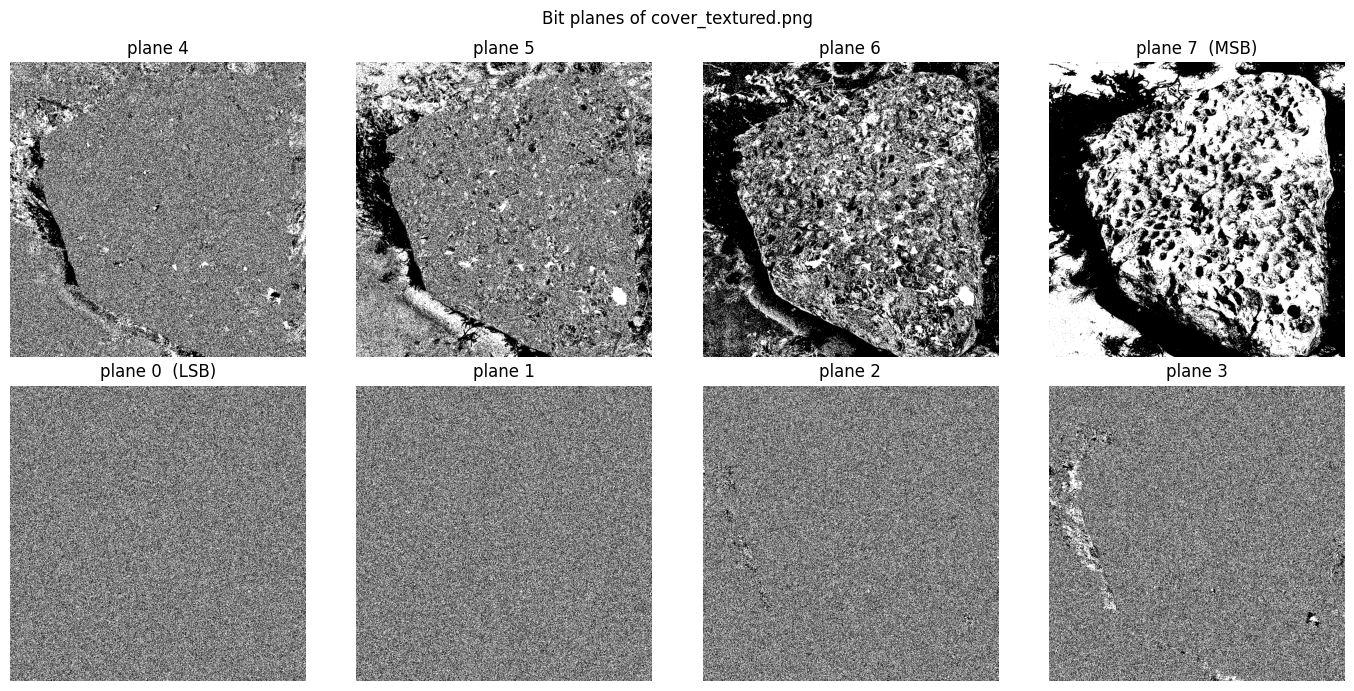

In [64]:
textured = np.asarray(Image.open(ROOT / "images/p2/cover_textured.png").convert("L")).astype(np.uint8)
smooth = np.asarray(Image.open(ROOT / "images/p2/cover_smooth.png").convert("L")).astype(np.uint8)

planes = bit_planes(textured)

fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for b in range(8):
    a = ax[1 - b // 4, b % 4]
    a.imshow(planes[b], cmap="gray", vmin=0, vmax=1)
    a.set_title(f"plane {b}" + ("  (LSB)" if b == 0 else "  (MSB)" if b == 7 else ""))
    a.axis("off")
plt.suptitle("Bit planes of cover_textured.png")
plt.tight_layout()
plt.show()

### PSNR against the number of retained planes

keep 1 planes: PSNR = 11.89 dB
keep 2 planes: PSNR = 16.92 dB
keep 3 planes: PSNR = 23.00 dB
keep 4 planes: PSNR = 29.23 dB
keep 5 planes: PSNR = 35.71 dB
keep 6 planes: PSNR = 42.69 dB
keep 7 planes: PSNR = 51.14 dB
keep 8 planes: PSNR = inf dB

per-plane gain: 5.03 6.08 6.23 6.48 6.98 8.45 dB
mean gain      : 6.54 dB    20*log10(2) = 6.02 dB


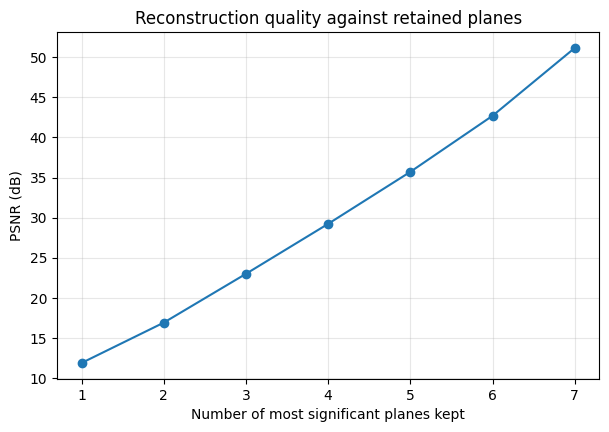

In [65]:
keeps = range(1, 9)
scores = [psnr(reconstruct(planes, k), textured) for k in keeps]

for k, s in zip(keeps, scores):
    print(f"keep {k} planes: PSNR = {s:.2f} dB")

gains = np.diff(scores[:-1])   # last step is to infinity
print("\nper-plane gain:", " ".join(f"{g:.2f}" for g in gains), "dB")
print("mean gain      :", f"{gains.mean():.2f} dB    20*log10(2) = {20 * np.log10(2):.2f} dB")

plt.figure(figsize=(7, 4.5))
plt.plot(list(keeps)[:-1], scores[:-1], marker="o")
plt.xlabel("Number of most significant planes kept")
plt.ylabel("PSNR (dB)")
plt.title("Reconstruction quality against retained planes")
plt.grid(True, alpha=0.3)
plt.show()

**Measure the gain per plane and explain why that value is not a coincidence.**

The measured gains are 5.03, 6.08, 6.23, 6.48, 6.98 and 8.45 dB, so each extra plane is worth
close to **6 dB**.

Keeping the top $n$ planes is the same as quantising the intensity with step
$\Delta = 2^{8-n}$. Adding one more plane halves $\Delta$, which divides the mean squared
error by 4, so the PSNR rises by

$$10\log_{10} 4 = 20\log_{10} 2 = 6.02\ \text{dB}.$$

This is the 6 dB per bit rule. It is not a coincidence: one extra bit doubles the number of
levels, and doubling the resolution is a factor of 4 in error power. It follows from binary
place value, so any image gives the same 6 dB.

The gain drifts above 6 dB at the fine end and falls below it at the coarse end, where only
one or two planes remain and the quantisation error is no longer small compared with the
signal itself.

### The intensity ramp, binary against Gray code

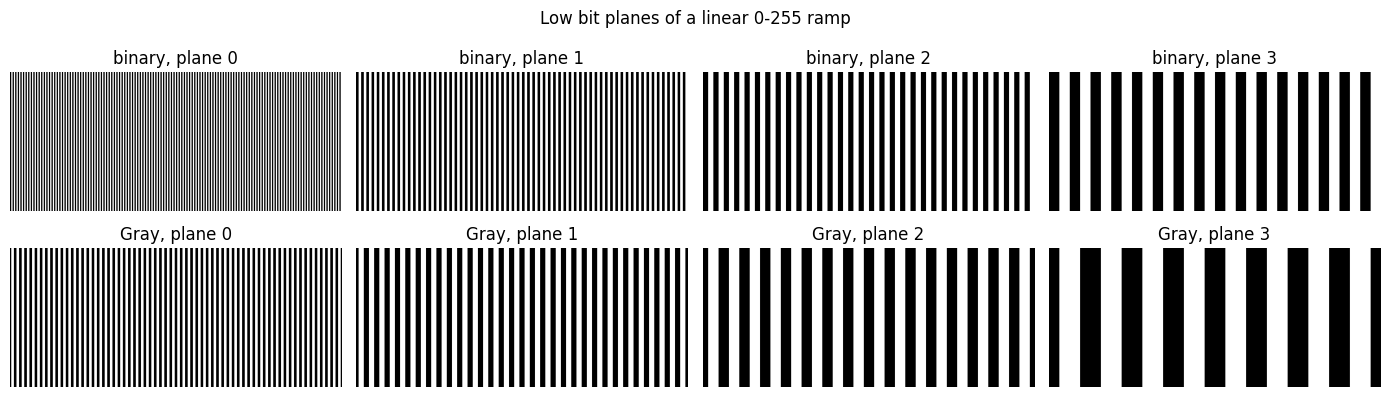

In [66]:
ramp = np.tile(np.arange(256, dtype=np.uint8), (64, 1))
ramp_planes = bit_planes(ramp)
gray_planes = bit_planes(gray_encode(ramp))

fig, ax = plt.subplots(2, 4, figsize=(14, 4))
for b in range(4):
    ax[0, b].imshow(ramp_planes[b], cmap="gray", vmin=0, vmax=1, aspect="auto")
    ax[0, b].set_title(f"binary, plane {b}")
    ax[1, b].imshow(gray_planes[b], cmap="gray", vmin=0, vmax=1, aspect="auto")
    ax[1, b].set_title(f"Gray, plane {b}")
for a in ax.ravel():
    a.axis("off")
plt.suptitle("Low bit planes of a linear 0-255 ramp")
plt.tight_layout()
plt.show()

**Identify the structure the low planes of the ramp show that the natural image does not, then
explain the difference under Gray coding.**

The ramp's low planes are exact **periodic square waves**: plane $b$ toggles every $2^b$
columns, so it has period $2^{b+1}$. Plane 0 alternates every column, plane 1 every two
columns, and so on. The same planes of the photograph look like noise.

The reason is the content, not the slicing. The ramp's intensity is a deterministic function
of position, so its low bits are too. In a photograph the low bits are set by sensor noise and
fine texture, which are uncorrelated between neighbouring pixels. Bit planes are therefore not
inherently noisy — that is what makes the LSB a good hiding place in 2.2.

**Under Gray coding** consecutive levels differ in exactly one bit, so a one-level step flips
one plane instead of several. In straight binary the planes all switch together at the
$2^b$ boundaries, which is what produces the aligned nested square waves, and at $127 \to 128$
all eight bits flip at once for a change of one grey level. The Gray planes still alternate
but their transitions are staggered rather than aligned, and no position has many planes
switching together. The practical benefit is that a single corrupted bit can no longer move
the intensity by 128 levels.

## 2.2 — Hide and recover a payload

### Decode the supplied stego image

In [67]:
stego_given = np.asarray(Image.open(ROOT / "images/p2/decode_me.png").convert("L")).astype(np.uint8)

allbits = extract_lsb(stego_given, stego_given.size)

sync = allbits[:8]
print("sync marker :", sync, " expected [1 0 1 0 1 0 1 0]")
print("sync ok     :", np.array_equal(sync, np.array([1, 0, 1, 0, 1, 0, 1, 0], dtype=np.uint8)))

ph = int("".join(map(str, allbits[8:16])), 2)
pw = int("".join(map(str, allbits[16:24])), 2)
print(f"payload     : {ph} x {pw} = {ph * pw} bits")

payload = allbits[24 : 24 + ph * pw].reshape(ph, pw)

sync marker : [1 0 1 0 1 0 1 0]  expected [1 0 1 0 1 0 1 0]
sync ok     : True
payload     : 64 x 64 = 4096 bits


### Recovered payload, PSNR, and difference map

PSNR(stego, clean cover) = 75.24 dB
max |stego - cover|      = 1
pixels changed           = 2039 of 4120 bit-carrying positions (49.5%)


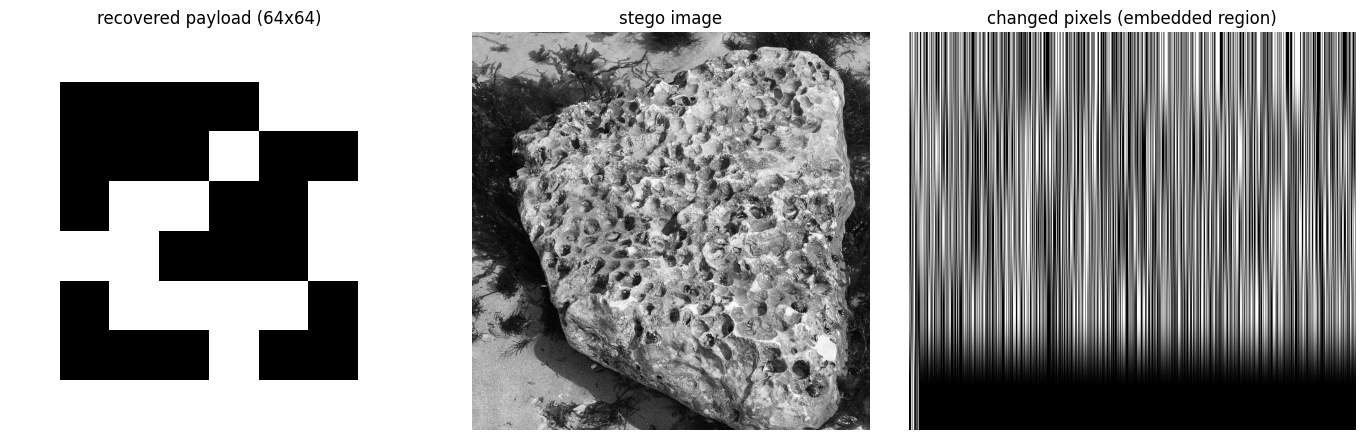

In [68]:
diff = (stego_given.astype(int) != textured.astype(int))
n_carrying = 24 + ph * pw

print(f"PSNR(stego, clean cover) = {psnr(stego_given, textured):.2f} dB")
print(f"max |stego - cover|      = {np.abs(stego_given.astype(int) - textured.astype(int)).max()}")
print(f"pixels changed           = {diff.sum()} of {n_carrying} bit-carrying positions "
      f"({diff.sum() / n_carrying:.1%})")

fig, ax = plt.subplots(1, 3, figsize=(14, 4.5))
ax[0].imshow(payload, cmap="gray"); ax[0].set_title(f"recovered payload ({ph}x{pw})")
ax[1].imshow(stego_given, cmap="gray"); ax[1].set_title("stego image")
ax[2].imshow(diff[: n_carrying // 1024 + 1], cmap="gray", aspect="auto")
ax[2].set_title("changed pixels (embedded region)")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

**Say whether you could have detected the payload by eye, and account for why only about half
of the bit-carrying positions actually changed.**

**No.** The embedding only ever touches bit 0, so no pixel moves by more than one grey level
out of 256, giving a PSNR of 75.24 dB — far above the roughly 40 dB at which distortion starts
to be visible. The difference map does show the payload clearly, but computing it needs the
clean cover, which is exactly what a steganalyst does not have.

**On the count.** 2039 of the 4120 bit-carrying positions differ, about 49.5%. Every one of
those positions was written; the write is simply a no-op wherever the cover's original LSB
already equalled the bit being embedded, which for uncorrelated data happens half the time. So
counting changed pixels undercounts the positions actually used by a factor of two, and a
steganalyst working from that count would underestimate the payload length by the same factor.

### The same payload in both covers

The handout asks for at least 256x256 bits, so the recovered payload is upsampled by 4 in each
direction to give 65 536 bits.

In [69]:
big_payload = np.kron(payload, np.ones((4, 4), dtype=np.uint8))
print("enlarged payload:", big_payload.shape, "=", big_payload.size, "bits")

stego_t = embed_lsb(textured, big_payload.ravel())
stego_s = embed_lsb(smooth, big_payload.ravel())

R = big_payload.size // 1024          # embedded region = first R rows

print(f"\n{'cover':10s} {'PSNR (dB)':>10} {'pixels changed':>16}")
for name, c, s in [("textured", textured, stego_t), ("smooth", smooth, stego_s)]:
    print(f"{name:10s} {psnr(c, s):10.2f} {int((c != s).sum()):16d}")

enlarged payload: (256, 256) = 65536 bits

cover       PSNR (dB)   pixels changed
textured        63.16            32921
smooth          63.19            32692


PSNR and the change counts are effectively identical, so the evidence for which cover is the
worse hiding place has to be local rather than global.

In [70]:
print(f"{'cover':10s} {'median tile var':>16} {'noise / local var':>19}")

for name, c, s in [("textured", textured, stego_t), ("smooth", smooth, stego_s)]:
    reg = c[:R].astype(np.float64)
    v = reg.reshape(R // 8, 8, 128, 8).swapaxes(1, 2).var(axis=(2, 3)).ravel()
    d = (s[:R].astype(np.float64) - reg) ** 2
    tn = d.reshape(R // 8, 8, 128, 8).swapaxes(1, 2).mean(axis=(2, 3)).ravel()
    print(f"{name:10s} {np.median(v):16.2f} {np.median(tn / np.maximum(v, 1e-9)):19.5f}")

cover       median tile var   noise / local var
textured             207.94             0.00241
smooth                13.17             0.03775


**Show which cover is the materially worse hiding place, and explain why PSNR cannot see it.**

The **smooth** cover is the worse hiding place. The embedding is identical in both cases —
same payload, same positions, same $\pm 1$ change, and the same number of modified pixels — so
the PSNRs come out at 63.16 dB and 63.19 dB, indistinguishable.

What differs is what the change has to hide behind. In the embedded region the median $8\times8$
tile variance is about **208** for the textured cover and **13** for the smooth one. Measuring
the embedding as a fraction of the local signal it must hide in gives $2.4\times10^{-3}$ against
$3.8\times10^{-2}$, so the perturbation is roughly **16 times larger relative to local content**
in the smooth cover.

PSNR cannot see this because it is a single global average of squared error. It depends only on
how much total error energy was added, not on where that energy landed or what was underneath
it. Two embeddings that flip the same number of pixels by one level have almost the same PSNR
whatever the cover. Detectability, by contrast, depends on the error *relative to local
content*: a one-level change on texture spanning tens of levels is masked, while the same change
on a near-constant patch is a large share of the local range. Any argument about hiding places
therefore needs a local measure, which is why the tile-variance ratio is the evidence here.

## 2.3 — Survive the channel

Block-DCT QIM: one coefficient (2,2) per JPEG-aligned 8x8 block, bit 0 on the lattice {k*48}
and bit 1 on {k*48 + 24}, each of the 128 bits repeated over 128 blocks and majority-voted.

In [71]:
# Orthonormal 8x8 DCT-II matrix, built with NumPy (no scipy)
_k = np.arange(8)
_D = np.cos(np.pi * (2 * _k[None, :] + 1) * _k[:, None] / 16)
_D[0, :] *= np.sqrt(1 / 8)
_D[1:, :] *= np.sqrt(2 / 8)


def _to_blocks(img):
    H, W = img.shape
    return img.reshape(H // 8, 8, W // 8, 8).swapaxes(1, 2)


def _from_blocks(blocks):
    nh, nw = blocks.shape[:2]
    return blocks.swapaxes(1, 2).reshape(nh * 8, nw * 8)


def _bit_of_block(nb, n, seed):
    """Which bit each block carries, under a fixed pseudorandom scatter."""
    order = np.random.default_rng(seed).permutation(nb)
    assign = np.empty(nb, dtype=np.int64)
    assign[order] = np.arange(nb) % n
    return assign


def embed_robust(cover, bits, delta=48.0, coef=(2, 2), seed=12345):
    bits = np.asarray(bits, dtype=np.uint8).ravel()
    n = len(bits)
    u, v = coef

    blocks = _to_blocks(cover.astype(np.float64))
    nh, nw = blocks.shape[:2]
    nb = nh * nw

    C = (_D @ blocks @ _D.T).reshape(nb, 8, 8)

    carried = bits[_bit_of_block(nb, n, seed)]
    offset = np.where(carried == 1, delta / 2, 0.0)

    c = C[:, u, v]
    C[:, u, v] = delta * np.round((c - offset) / delta) + offset

    rec = _D.T @ C.reshape(nh, nw, 8, 8) @ _D

    return np.clip(np.round(_from_blocks(rec)), 0, 255).astype(np.uint8)


def extract_robust(stego, cover, n, delta=48.0, coef=(2, 2), seed=12345):
    """Blind: `cover` is accepted to match the starter signature, never read."""
    u, v = coef

    blocks = _to_blocks(stego.astype(np.float64))
    nh, nw = blocks.shape[:2]
    nb = nh * nw

    c = (_D @ blocks @ _D.T).reshape(nb, 8, 8)[:, u, v]

    res = np.mod(c, delta)
    d0 = np.minimum(res, delta - res)
    d1 = np.abs(res - delta / 2)
    hard = (d1 < d0).astype(np.int64)

    assign = _bit_of_block(nb, n, seed)
    votes = np.bincount(assign, weights=hard, minlength=n)
    counts = np.bincount(assign, minlength=n)

    return (votes > counts / 2).astype(np.uint8)

### Stego PSNR and clean recovery

In [72]:
message = np.random.default_rng(7).integers(0, 2, 128).astype(np.uint8)

stego_qim = embed_robust(textured, message)
stego_naive = embed_lsb(textured, message)

print(f"PSNR(cover, QIM stego) = {psnr(textured, stego_qim):.2f} dB   (requirement >= 40)")
print(f"clean BER              = {ber(extract_robust(stego_qim, textured, 128), message)}")
print(f"max |cover - stego|    = {np.abs(textured.astype(int) - stego_qim.astype(int)).max()} levels")

PSNR(cover, QIM stego) = 43.11 dB   (requirement >= 40)
clean BER              = 0.0
max |cover - stego|    = 5 levels


/var/folders/25/8mg9n8qj4zdd3515lddjzdph0000gn/T/ipykernel_30455/229203528.py:35: RuntimeWarning: divide by zero encountered in matmul
  C = (_D @ blocks @ _D.T).reshape(nb, 8, 8)
/var/folders/25/8mg9n8qj4zdd3515lddjzdph0000gn/T/ipykernel_30455/229203528.py:35: RuntimeWarning: overflow encountered in matmul
  C = (_D @ blocks @ _D.T).reshape(nb, 8, 8)
/var/folders/25/8mg9n8qj4zdd3515lddjzdph0000gn/T/ipykernel_30455/229203528.py:35: RuntimeWarning: invalid value encountered in matmul
  C = (_D @ blocks @ _D.T).reshape(nb, 8, 8)
/var/folders/25/8mg9n8qj4zdd3515lddjzdph0000gn/T/ipykernel_30455/229203528.py:43: RuntimeWarning: divide by zero encountered in matmul
  rec = _D.T @ C.reshape(nh, nw, 8, 8) @ _D
/var/folders/25/8mg9n8qj4zdd3515lddjzdph0000gn/T/ipykernel_30455/229203528.py:43: RuntimeWarning: overflow encountered in matmul
  rec = _D.T @ C.reshape(nh, nw, 8, 8) @ _D
/var/folders/25/8mg9n8qj4zdd3515lddjzdph0000gn/T/ipykernel_30455/229203528.py:43: RuntimeWarning: invalid value enc

### BER against both channels, mine and naive LSB

In [73]:
sigmas = [0, 1, 2, 5, 10, 20]
ber_qim, ber_naive = [], []

for s in sigmas:
    ber_qim.append(ber(extract_robust(degrade_gaussian(stego_qim, s), textured, 128), message))
    ber_naive.append(ber(extract_lsb(degrade_gaussian(stego_naive, s), 128), message))

jpeg_qim = ber(extract_robust(degrade_jpeg(stego_qim, 75), textured, 128), message)
jpeg_naive = ber(extract_lsb(degrade_jpeg(stego_naive, 75), 128), message)

print(f"{'sigma':>6} {'QIM BER':>10} {'naive BER':>11}")
for s, a, b in zip(sigmas, ber_qim, ber_naive):
    print(f"{s:6d} {a:10.4f} {b:11.4f}")

print(f"\nJPEG q75   QIM BER = {jpeg_qim:.4f}    naive BER = {jpeg_naive:.4f}")
print("\nrequirement: zero errors at sigma=5 and at JPEG q75")
print(f"  sigma=5  : {'PASS' if ber_qim[sigmas.index(5)] == 0 else 'FAIL'}")
print(f"  JPEG q75 : {'PASS' if jpeg_qim == 0 else 'FAIL'}")

/var/folders/25/8mg9n8qj4zdd3515lddjzdph0000gn/T/ipykernel_30455/229203528.py:56: RuntimeWarning: divide by zero encountered in matmul
  c = (_D @ blocks @ _D.T).reshape(nb, 8, 8)[:, u, v]
/var/folders/25/8mg9n8qj4zdd3515lddjzdph0000gn/T/ipykernel_30455/229203528.py:56: RuntimeWarning: overflow encountered in matmul
  c = (_D @ blocks @ _D.T).reshape(nb, 8, 8)[:, u, v]
/var/folders/25/8mg9n8qj4zdd3515lddjzdph0000gn/T/ipykernel_30455/229203528.py:56: RuntimeWarning: invalid value encountered in matmul
  c = (_D @ blocks @ _D.T).reshape(nb, 8, 8)[:, u, v]


 sigma    QIM BER   naive BER
     0     0.0000      0.0000
     1     0.0000      0.5625
     2     0.0000      0.5781
     5     0.0000      0.5625
    10     0.0000      0.5000
    20     0.2422      0.5156

JPEG q75   QIM BER = 0.0000    naive BER = 0.5391

requirement: zero errors at sigma=5 and at JPEG q75
  sigma=5  : PASS
  JPEG q75 : PASS


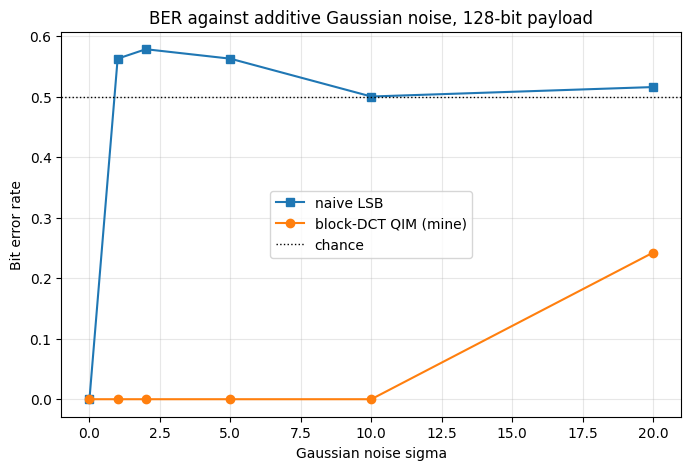

In [74]:
plt.figure(figsize=(8, 5))
plt.plot(sigmas, ber_naive, marker="s", label="naive LSB")
plt.plot(sigmas, ber_qim, marker="o", label="block-DCT QIM (mine)")
plt.axhline(0.5, color="k", ls=":", lw=1, label="chance")
plt.xlabel("Gaussian noise sigma")
plt.ylabel("Bit error rate")
plt.title("BER against additive Gaussian noise, 128-bit payload")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### (a) Does the decoder need the clean cover?

**Blind** — `extract_robust` accepts `cover` only to match the starter signature and never
reads it. QIM is blind by construction: the bit is carried by *which lattice* the coefficient
was quantised onto, and that is an absolute property of the received value rather than a
comparison against an original.

A cover-assisted decoder is solving an easier problem, since it can subtract the original and
read the residual directly, which tolerates far more channel damage. The cost is that the
receiver must already hold the entire cover image, which in most realistic uses defeats the
point of hiding data in it. Going the other way, from cover-assisted to blind, is the hard
direction and needs exactly what I used here: a quantisation-based rather than
difference-based embedding, so the decision rule requires no reference.

### (b) What are you trading?

$\mathrm{PSNR} \ge 40$ dB means $\mathrm{MSE} \le 255^2/10^4 = 6.50$, so the total squared
error allowed over the image is $6.50 \times 1024^2 = 6.8\times10^6$. My scheme spends
$\mathrm{MSE} = 3.18$, a total of $3.3\times10^6$, which is about half the budget and lands at
43.11 dB.

So the 40 dB floor is **not** the binding constraint at 128 bits. I could roughly double the
step and still pass; I do not need to, because the error rate is already zero with margin. What
the spare budget buys is redundancy: all 16 384 blocks are used to carry 128 bits, a ratio of
128:1.

### Design paragraph

The problem fixes the payload at 128 bits and fixes imperceptibility at 40 dB, which leaves
redundancy as the only free variable, so I spent it all on robustness and gave up capacity. The
same scheme at one bit per block would carry 16 384 bits — 128 times the payload — but each bit
would then rest on a single coefficient and would no longer survive $\sigma = 5$. Instead each
bit is repeated over 128 scattered blocks and majority-voted, which turns a small per-block
error rate into zero bit errors, and I finish at 43 dB with distortion budget still unspent. I
therefore sit in the corner of the triangle that sacrifices rate to buy robustness, which is the
right corner when the payload is fixed at 128 bits in a megapixel image.

### What each channel breaks

The two channels fail different designs, which is why meeting both is the real constraint.
Gaussian noise is broadband and random: it perturbs every coefficient a little and so destroys
anything whose decision margin is smaller than the noise. Naive LSB has a margin of half a grey
level and is already at chance by $\sigma = 1$. The defence is a large margin plus averaging,
which $\Delta = 48$ and the 128-fold repetition provide.

JPEG is deterministic and does not add noise so much as delete information: it discards high
frequencies outright and coarsely requantises the rest. A scheme hiding data in high
frequencies, or one whose lattice is misaligned with the JPEG quantiser, is destroyed no matter
how large its margin. Choosing a mid-low coefficient and making both $\Delta$ and $\Delta/2$
multiples of the JPEG q75 step means requantisation lands back on the lattice, so JPEG costs
essentially nothing. The scheme finally fails at $\sigma = 20$ (BER 0.24), where per-block
errors approach the level no amount of voting can recover.

---
# Problem 3 — Piecewise linear transforms

One pointwise piecewise-linear transform was applied to each input/output pair:

- A: `field_in.png` -> `field_out_A.png` (levels operation)
- B: `field_in.png` -> `field_out_B.png` (grey-level slicing, not monotonic)
- C: `nebula_in.png` -> `nebula_out_C.png` (segment count not given)
- D: `field_skycrop_in.png` -> `field_skycrop_out_D.png` (mostly sky, four true segments)

In [75]:
def load_p3(name):
    return np.asarray(Image.open(ROOT / "images/p3" / name).convert("L"))


def transfer_curve(img_in, img_out):
    """T[v] = the output level for input level v, cnt[v] = pixels supporting it.

    Unsampled levels get T = nan, so they stay distinguishable from levels that
    genuinely map to zero.
    """
    cnt = np.bincount(img_in.ravel(), minlength=256).astype(float)
    T = np.full(256, np.nan)

    for v in np.flatnonzero(cnt):
        T[v] = np.median(img_out[img_in == v])

    return T, cnt

In [76]:
QUANT_FLOOR = 1 / 12    # variance of rounding a real number to the nearest integer


def fit_piecewise(T, cnt, max_seg=6, min_count=1, force_seg=None):
    """Fit the fewest segments the data justifies.

    The output is an 8-bit lookup table, so rounding alone leaves a mean squared
    residual of about 1/12. Once a fit reaches that floor it is describing the
    quantisation rather than the transform, so we stop there.

    Returns (breakpoints, slopes, intercepts, n_segments, rss_by_segment_count).
    """
    v = np.flatnonzero((cnt >= min_count) & ~np.isnan(T)).astype(float)
    y = T[v.astype(int)]
    m = len(v)

    # sse[i, j] = squared error of one straight line through levels v[i:j]
    sse = np.full((m + 1, m + 1), np.inf)
    for i in range(m):
        for j in range(i + 2, m + 1):
            x, yy = v[i:j], y[i:j]
            dx = x - x.mean()
            slope = (dx * (yy - yy.mean())).sum() / (dx * dx).sum()
            sse[i, j] = np.sum((slope * x + (yy.mean() - slope * x.mean()) - yy) ** 2)

    # best[s, j] = lowest error using s segments to cover the first j levels
    best = np.full((max_seg + 1, m + 1), np.inf)
    best[0, 0] = 0.0
    back = np.zeros((max_seg + 1, m + 1), dtype=int)

    for s in range(1, max_seg + 1):
        for j in range(2 * s, m + 1):
            for i in range(2 * (s - 1), j - 1):
                total = best[s - 1, i] + sse[i, j]
                if total < best[s, j]:
                    best[s, j] = total
                    back[s, j] = i

    rss = best[1:, m]

    # smallest segment count whose residual has reached the quantisation floor
    ok = np.flatnonzero(rss / m <= QUANT_FLOOR)
    n_seg = int(ok[0]) + 1 if len(ok) else max_seg

    if force_seg is not None:
        n_seg = force_seg

    # walk the choices back to get the segments
    bps, slopes, inters = [], [], []
    j, s = m, n_seg
    while s > 0:
        i = back[s, j]
        x, yy = v[i:j], y[i:j]
        dx = x - x.mean()
        slope = (dx * (yy - yy.mean())).sum() / (dx * dx).sum()
        bps.append((v[i], v[j - 1]))
        slopes.append(slope)
        inters.append(yy.mean() - slope * x.mean())
        j, s = i, s - 1

    return bps[::-1], slopes[::-1], inters[::-1], n_seg, rss

In [77]:
def apply_recovered(img, bps, slopes, inter):
    """Build the LUT from the fitted segments and apply it."""
    lut = np.zeros(256)

    for (lo, hi), s, c in zip(bps, slopes, inter):
        v = np.arange(int(lo), int(hi) + 1)
        lut[v] = s * v + c

    return np.clip(np.round(lut), 0, 255).astype(np.uint8)[img]


def support_report(cnt, min_count=20):
    """Which intensity ranges the input samples well enough to constrain T."""
    sup = np.flatnonzero(cnt >= min_count)
    weak = np.flatnonzero((cnt > 0) & (cnt < min_count))

    lines = [f"threshold: a level needs at least {min_count} pixels",
             f"trusted levels : {len(sup)} of 256, spanning {sup.min()}-{sup.max()}",
             f"too few pixels : {len(weak)} levels",
             f"never sampled  : {int(np.sum(cnt == 0))} levels"]

    return "\n".join(lines)


def show_fit(T, cnt, bps, slopes, inter, title):
    """Measured scatter with the fitted curve on top."""
    v = np.flatnonzero(~np.isnan(T))

    plt.figure(figsize=(7, 5))
    plt.scatter(v, T[v], s=8, label="measured T[v]")
    for (lo, hi), s, c in zip(bps, slopes, inter):
        x = np.arange(int(lo), int(hi) + 1)
        plt.plot(x, s * x + c, "r-", lw=2)
    plt.plot([], [], "r-", lw=2, label="fitted segments")
    plt.xlabel("input level v")
    plt.ylabel("output level T[v]")
    plt.title(title)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

## 3.1 — Recover two known transforms

### A: levels operation

segments chosen: 3

   input range     slope   intercept
        0 - 12     0.000        0.00
       13 - 60     3.969      -48.36
      61 - 255     0.333      169.66

re-applied against true output: max |err| = 0, mean |err| = 0.0000


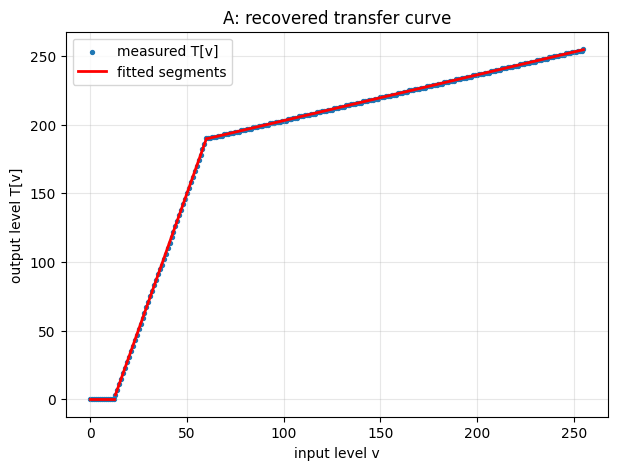

In [78]:
inA = load_p3("field_in.png")
outA = load_p3("field_out_A.png")

TA, cntA = transfer_curve(inA, outA)
bpsA, slA, itA, nA, rssA = fit_piecewise(TA, cntA)

print(f"segments chosen: {nA}\n")
print(f"{'input range':>14} {'slope':>9} {'intercept':>11}")
for (lo, hi), s, c in zip(bpsA, slA, itA):
    print(f"{f'{lo:.0f} - {hi:.0f}':>14} {s:9.3f} {c:11.2f}")

recA = apply_recovered(inA, bpsA, slA, itA)
err = np.abs(recA.astype(int) - outA.astype(int))
print(f"\nre-applied against true output: max |err| = {err.max()}, mean |err| = {err.mean():.4f}")

show_fit(TA, cntA, bpsA, slA, itA, "A: recovered transfer curve")

### B: grey-level slicing

segments chosen: 4

   input range     slope   intercept
        0 - 69     0.285       -0.40
      70 - 110     5.375     -356.64
     111 - 150    -5.373      825.54
     151 - 255    -0.190       48.03

re-applied against true output: max |err| = 0, mean |err| = 0.0000


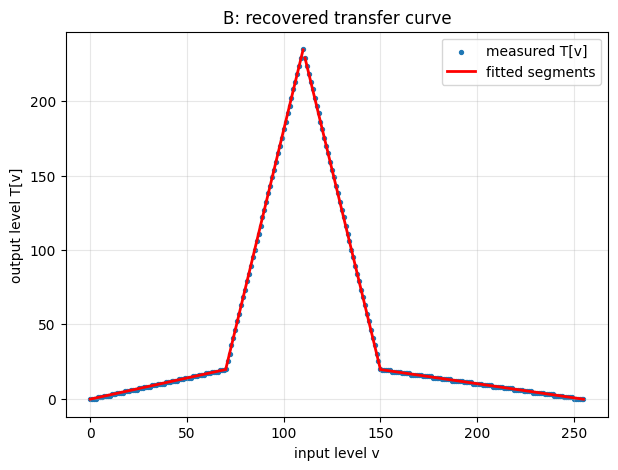

In [79]:
inB = load_p3("field_in.png")
outB = load_p3("field_out_B.png")

TB, cntB = transfer_curve(inB, outB)
bpsB, slB, itB, nB, rssB = fit_piecewise(TB, cntB)

print(f"segments chosen: {nB}\n")
print(f"{'input range':>14} {'slope':>9} {'intercept':>11}")
for (lo, hi), s, c in zip(bpsB, slB, itB):
    print(f"{f'{lo:.0f} - {hi:.0f}':>14} {s:9.3f} {c:11.2f}")

recB = apply_recovered(inB, bpsB, slB, itB)
err = np.abs(recB.astype(int) - outB.astype(int))
print(f"\nre-applied against true output: max |err| = {err.max()}, mean |err| = {err.mean():.4f}")

show_fit(TB, cntB, bpsB, slB, itB, "B: recovered transfer curve")

**B is recoverable from the pair but not invertible from the output alone. Explain the
difference in one sentence.**

_TODO_

## 3.2 — Choose the number of segments

C is not told how many segments it has, so the count has to come from the data.

 segments          RSS   RSS / level
        1    190530.82      750.1214
        2     19158.12       75.4257
        3       639.86        2.5191
        4        20.46        0.0806  <- chosen
        5        20.05        0.0789
        6        19.64        0.0773

quantisation floor = 1/12 = 0.0833
segments chosen    = 4

   input range     slope   intercept
        1 - 39     0.376        4.53
      40 - 120     2.250      -70.35
     121 - 198     0.313      161.94
     199 - 255     0.545      115.64

re-applied against true output: max |err| = 0, mean |err| = 0.0000


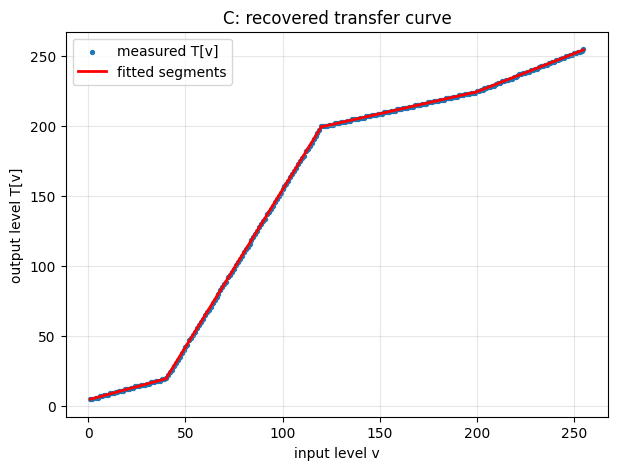

In [80]:
inC = load_p3("nebula_in.png")
outC = load_p3("nebula_out_C.png")

TC, cntC = transfer_curve(inC, outC)
bpsC, slC, itC, nC, rssC = fit_piecewise(TC, cntC)

m = int(np.sum(~np.isnan(TC)))

print(f"{'segments':>9} {'RSS':>12} {'RSS / level':>13}")
for s, r in enumerate(rssC, 1):
    mark = "  <- chosen" if s == nC else ""
    print(f"{s:9d} {r:12.2f} {r / m:13.4f}{mark}")

print(f"\nquantisation floor = 1/12 = {1 / 12:.4f}")
print(f"segments chosen    = {nC}\n")

print(f"{'input range':>14} {'slope':>9} {'intercept':>11}")
for (lo, hi), s, c in zip(bpsC, slC, itC):
    print(f"{f'{lo:.0f} - {hi:.0f}':>14} {s:9.3f} {c:11.2f}")

recC = apply_recovered(inC, bpsC, slC, itC)
err = np.abs(recC.astype(int) - outC.astype(int))
print(f"\nre-applied against true output: max |err| = {err.max()}, mean |err| = {err.mean():.4f}")

show_fit(TC, cntC, bpsC, slC, itC, "C: recovered transfer curve")

### Forcing more segments than the data supports

In [81]:
# force more segments than the data supports and look at what they do
bps6, sl6, it6, _, _ = fit_piecewise(TC, cntC, force_seg=6)

print("forced 6-segment fit:")
print(f"{'input range':>14} {'slope':>9}")
for (lo, hi), sl in zip(bps6, sl6):
    print(f"{f'{lo:.0f} - {hi:.0f}':>14} {sl:9.3f}")

print(f"\nRSS at {nC} segments: {rssC[nC - 1]:.2f}   at 6 segments: {rssC[5]:.2f}")
print(f"improvement: {rssC[nC - 1] - rssC[5]:.2f} over {6 - nC} extra segments")

forced 6-segment fit:
   input range     slope
        1 - 39     0.376
      40 - 119     2.249
     120 - 123     0.000
     124 - 198     0.313
     199 - 252     0.545
     253 - 255     1.000

RSS at 4 segments: 20.46   at 6 segments: 19.64
improvement: 0.82 over 2 extra segments


**State the complexity penalty you used and why, and show that your method is not fitting the
quantisation of the output lookup table.**

_TODO_

## 3.3 — Identifiability

D is a crop of almost nothing but sky, so only a narrow band of input levels is well sampled.

threshold: a level needs at least 20 pixels
trusted levels : 63 of 256, spanning 1-75
too few pixels : 176 levels
never sampled  : 17 levels


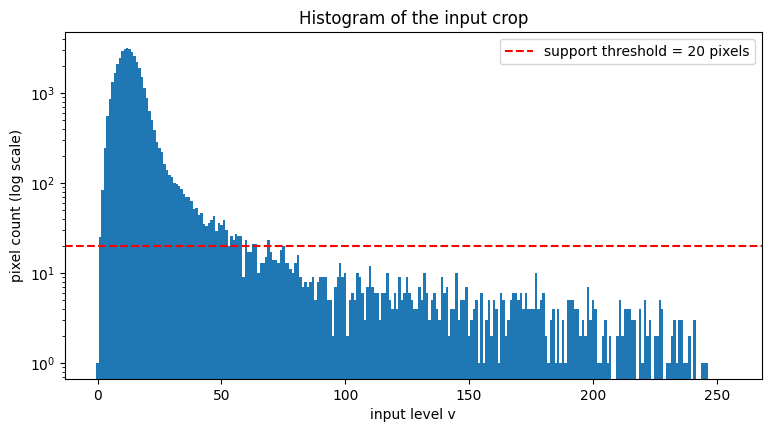

In [82]:
inD = load_p3("field_skycrop_in.png")
outD = load_p3("field_skycrop_out_D.png")

TD, cntD = transfer_curve(inD, outD)

MIN_COUNT = 20

print(support_report(cntD, MIN_COUNT))

plt.figure(figsize=(9, 4.5))
plt.bar(np.arange(256), cntD, width=1.0)
plt.axhline(MIN_COUNT, color="r", ls="--", label=f"support threshold = {MIN_COUNT} pixels")
plt.yscale("log")
plt.xlabel("input level v")
plt.ylabel("pixel count (log scale)")
plt.title("Histogram of the input crop")
plt.legend()
plt.show()

segments the data supports: 3

   input range     slope   intercept
        1 - 20     1.504       -0.29
       21 - 55     4.863      -67.78
       56 - 75     0.330      181.19

constrained over levels 1 - 75
unconstrained above level 75: 163 levels carry pixels but fewer than 20 each


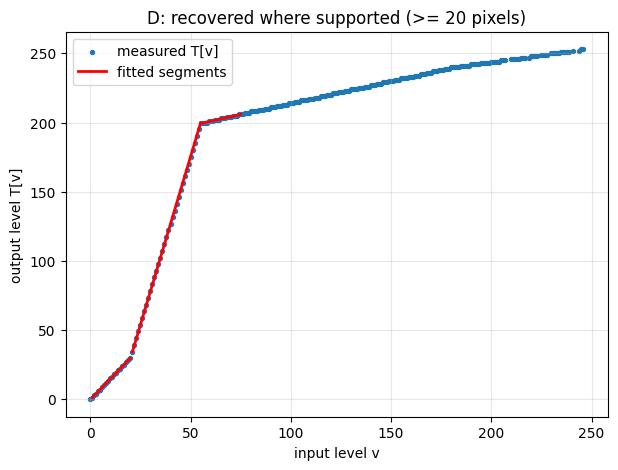

In [83]:
bpsD, slD, itD, nD, rssD = fit_piecewise(TD, cntD, min_count=MIN_COUNT)

sup = np.flatnonzero(cntD >= MIN_COUNT)

print(f"segments the data supports: {nD}\n")
print(f"{'input range':>14} {'slope':>9} {'intercept':>11}")
for (lo, hi), s, c in zip(bpsD, slD, itD):
    print(f"{f'{lo:.0f} - {hi:.0f}':>14} {s:9.3f} {c:11.2f}")

print(f"\nconstrained over levels {sup.min()} - {sup.max()}")
print(f"unconstrained above level {sup.max()}: "
      f"{int(np.sum((cntD > 0) & (np.arange(256) > sup.max())))} levels carry pixels "
      f"but fewer than {MIN_COUNT} each")

show_fit(TD, cntD, bpsD, slD, itD, f"D: recovered where supported (>= {MIN_COUNT} pixels)")

**(a) State the range of input levels actually sampled and justify your support threshold.**

_TODO_

**(b) Report the segments you can determine and the intensity range over which your answer is
unconstrained.**

_TODO_

**(c) How many segments did you report, and why is that not four?**

_TODO_